# Modelo e avaliação — EEGNet no BCI IV 2a

Predições do EEGNet (Lawhern et al., 2018) com `GroupKFold` por sujeito, 9 folds
([`../src/train.py`](../src/train.py)). Síntese na seção 13 do [`../README.md`](../README.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, confusion_matrix,
    f1_score, matthews_corrcoef,
)

data_dir = Path("..") / "data"
pred = pd.read_parquet(data_dir / "predictions" / "predictions_eegnet.parquet")
subjects = pd.read_parquet(data_dir / "processed" / "dim_subject.parquet")
CLASSES = ["left_hand", "right_hand", "feet", "tongue"]
pred["correct"] = pred["y_true"] == pred["y_pred"]
clean = pred[~pred["has_artifact"]]
print(pred["model_version"].unique(), len(pred), "predições,", pred["subject_id"].nunique(), "sujeitos")
pred.head()

<ArrowStringArray>
['eegnet_braindecode-1.8.1_groupkfold9_seed42_v2']
Length: 1, dtype: str 5184 predições, 9 sujeitos


,trial_id,subject_id,session_id,fold,model_version,y_true,has_artifact,y_pred,p_left_hand,p_right_hand,p_feet,p_tongue,correct
0,A09_0train_run_0_t00,A09,0train,0,eegnet_braindecode-1.8.1_groupkfold9_seed42_v2,3,True,3,7.717108e-13,1.130764e-07,0.006441,0.993559,True
1,A09_0train_run_0_t01,A09,0train,0,eegnet_braindecode-1.8.1_groupkfold9_seed42_v2,1,False,1,5.370467e-02,8.725196e-01,0.050886,0.022890,True
2,A09_0train_run_0_t02,A09,0train,0,eegnet_braindecode-1.8.1_groupkfold9_seed42_v2,1,False,2,3.716886e-01,1.442011e-01,0.481098,0.003012,False
3,A09_0train_run_0_t03,A09,0train,0,eegnet_braindecode-1.8.1_groupkfold9_seed42_v2,0,True,1,5.252288e-02,6.852990e-01,0.163602,0.098576,False
4,A09_0train_run_0_t04,A09,0train,0,eegnet_braindecode-1.8.1_groupkfold9_seed42_v2,3,True,3,1.135442e-06,1.674781e-10,0.095980,0.904019,True


## Divisão e prevalência

Sujeito de teste de cada fold e prevalência das classes (acaso = 25%).

In [2]:
pred.groupby("fold")["subject_id"].unique().rename("sujeito de teste").to_frame()

,sujeito de teste
fold,
0,[A09]
1,[A08]
2,[A07]
3,[A06]
4,[A05]
5,[A04]
6,[A03]
7,[A02]
8,[A01]


In [3]:
pd.DataFrame({
    "todos (%)": pred["y_true"].map(dict(enumerate(CLASSES))).value_counts(normalize=True) * 100,
    "sem artefato (%)": clean["y_true"].map(dict(enumerate(CLASSES))).value_counts(normalize=True) * 100,
}).round(1)

,todos (%),sem artefato (%)
y_true,,
feet,25.0,25.0
left_hand,25.0,24.8
right_hand,25.0,25.1
tongue,25.0,25.0


## Métricas com IC 95%

Trials sem artefato. IC por bootstrap reamostrando sujeitos (2.000 réplicas).

In [4]:
METRICS = {
    "acurácia": accuracy_score,
    "acurácia balanceada": balanced_accuracy_score,
    "F1 macro": lambda t, p: f1_score(t, p, average="macro"),
    "MCC": matthews_corrcoef,
}


def metrics_with_ci(df, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    by_subject = {s: g[["y_true", "y_pred"]].to_numpy() for s, g in df.groupby("subject_id")}
    ids = list(by_subject)
    reps = []
    for _ in range(n_boot):
        sample = np.concatenate([by_subject[s] for s in rng.choice(ids, len(ids))])
        reps.append([f(sample[:, 0], sample[:, 1]) for f in METRICS.values()])
    low, high = np.percentile(reps, [2.5, 97.5], axis=0)
    point = [f(df["y_true"], df["y_pred"]) for f in METRICS.values()]
    return pd.DataFrame({"valor": point, "IC 2,5%": low, "IC 97,5%": high}, index=list(METRICS))


summary = pd.concat({"sem artefato": metrics_with_ci(clean), "todos": metrics_with_ci(pred)}, axis=1)
summary.round(3)

sem artefato                   todos                 
                           valor IC 2,5% IC 97,5%  valor IC 2,5% IC 97,5%
acurácia                   0.494   0.417    0.573  0.490   0.416    0.568
acurácia balanceada        0.494   0.417    0.573  0.490   0.416    0.568
F1 macro                   0.496   0.408    0.572  0.493   0.410    0.567
MCC                        0.327   0.231    0.435  0.322   0.229    0.430

## Sensibilidade e especificidade por classe

Uma classe contra as demais, com IC 95% de Wilson.

In [5]:
def wilson(k, n):
    ci = stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return k / n, ci.low, ci.high


rows = []
for k, name in enumerate(CLASSES):
    pos, neg = clean[clean["y_true"] == k], clean[clean["y_true"] != k]
    sens = wilson((pos["y_pred"] == k).sum(), len(pos))
    spec = wilson((neg["y_pred"] != k).sum(), len(neg))
    rows.append({"classe": name, "sensibilidade": sens[0], "sens IC": f"{sens[1]:.2f}–{sens[2]:.2f}",
                 "especificidade": spec[0], "espec IC": f"{spec[1]:.2f}–{spec[2]:.2f}"})
pd.DataFrame(rows).round(3)

,classe,sensibilidade,sens IC,especificidade,espec IC
0,left_hand,0.518,0.49–0.55,0.798,0.78–0.81
1,right_hand,0.558,0.53–0.59,0.850,0.84–0.86
2,feet,0.454,0.43–0.48,0.765,0.75–0.78
3,tongue,0.445,0.42–0.47,0.912,0.90–0.92


## Matriz de confusão

Linhas = classe verdadeira; à direita, normalizada por linha.

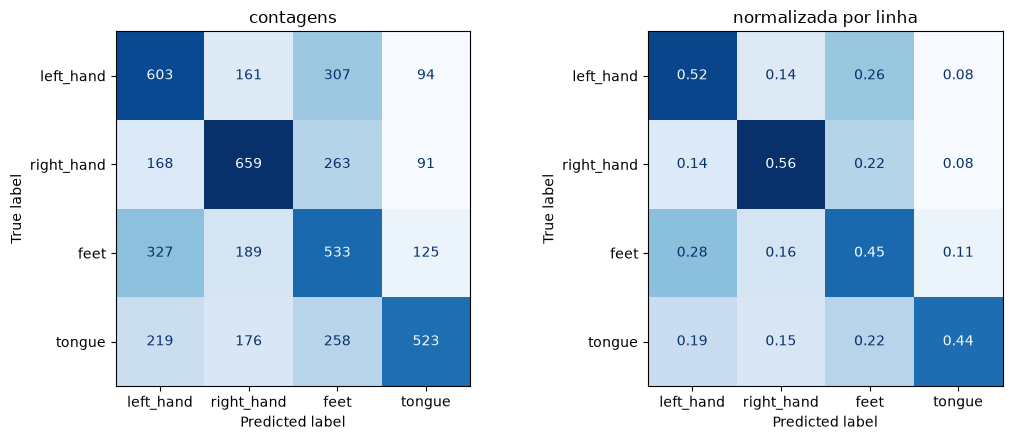

In [6]:
cm = confusion_matrix(clean["y_true"], clean["y_pred"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[0], colorbar=False, cmap="Blues")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(
    ax=axes[1], colorbar=False, cmap="Blues", values_format=".2f")
axes[0].set_title("contagens"); axes[1].set_title("normalizada por linha")
plt.tight_layout()

In [7]:
off = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(4) for j in range(4) if i != j]
pd.DataFrame(off, columns=["verdadeira", "predita", "trials"]).sort_values("trials", ascending=False).head(6)

,verdadeira,predita,trials
6,feet,left_hand,327
1,left_hand,feet,307
4,right_hand,feet,263
11,tongue,feet,258
9,tongue,left_hand,219
7,feet,right_hand,189


## Acurácia por sujeito

IC 95% de Wilson, trials sem artefato.

In [8]:
per_subject = clean.groupby("subject_id").agg(
    fold=("fold", "first"), n=("correct", "size"), acertos=("correct", "sum"))
ci = per_subject.apply(lambda r: wilson(r["acertos"], r["n"]), axis=1, result_type="expand")
per_subject[["acurácia", "IC 2,5%", "IC 97,5%"]] = ci
per_subject = per_subject.join(subjects.set_index("subject_id")[["age", "sex"]])
per_subject.round(3)

,fold,n,acertos,acurácia,"IC 2,5%","IC 97,5%",age,sex
subject_id,,,,,,,,
A01,8,554,369,0.666,0.626,0.704,22,F
A02,7,553,230,0.416,0.376,0.457,24,F
A03,6,543,345,0.635,0.594,0.675,26,M
A04,5,490,186,0.380,0.338,0.423,24,F
A05,4,538,176,0.327,0.289,0.368,24,M
A06,3,434,168,0.387,0.342,0.434,23,F
A07,2,548,244,0.445,0.404,0.487,25,M
A08,1,535,301,0.563,0.520,0.604,23,M
A09,0,501,299,0.597,0.553,0.639,17,M


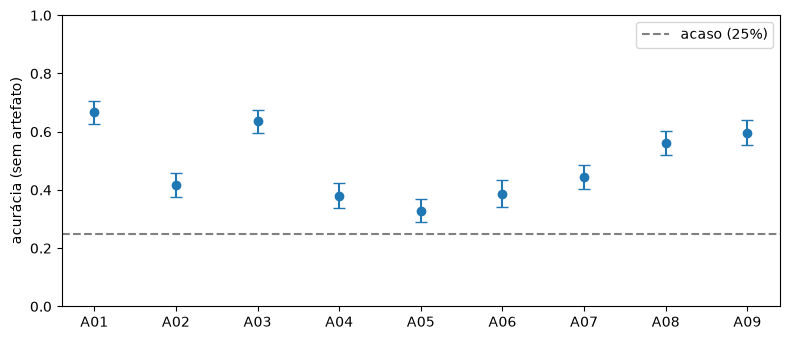

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
err = [per_subject["acurácia"] - per_subject["IC 2,5%"], per_subject["IC 97,5%"] - per_subject["acurácia"]]
ax.errorbar(per_subject.index, per_subject["acurácia"], yerr=err, fmt="o", capsize=4)
ax.axhline(0.25, ls="--", c="gray", label="acaso (25%)")
ax.set_ylabel("acurácia (sem artefato)"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout()

## Sessão e artefato

Qui-quadrado (Fisher se alguma frequência esperada for < 5), com correção de Holm.

In [10]:
def compare(df, column):
    table = pd.crosstab(df[column], df["correct"]).to_numpy()
    if (stats.contingency.expected_freq(table) < 5).any():
        return stats.fisher_exact(table)[1], "Fisher"
    return stats.chi2_contingency(table)[1], "qui-quadrado"


def holm(pvalues):
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues))
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, pvalues[i] * (len(pvalues) - rank)))
        adjusted[i] = running
    return adjusted


groups = {"session_id": clean, "has_artifact": pred}
tests = {column: compare(df, column) for column, df in groups.items()}
p_holm = holm([p for p, _ in tests.values()])
for (column, (p, name)), p_adj in zip(tests.items(), p_holm):
    print(f"{column}: {name}, p = {p:.3g}, p (Holm) = {p_adj:.3g}")
    display(groups[column].groupby(column)["correct"].agg(n="size", acurácia="mean").round(3))

session_id: qui-quadrado, p = 0.844, p (Holm) = 0.844


,n,acurácia
session_id,,
0train,2328,0.495
1test,2368,0.492


has_artifact: qui-quadrado, p = 0.0957, p (Holm) = 0.191


,n,acurácia
has_artifact,,
False,4696,0.494
True,488,0.453


## Limitações

- 9 sujeitos: IC largo, e o bootstrap com 9 grupos é aproximado.
- Domain shift entre pessoas: o teste é sempre um sujeito não visto, então os números não se
  comparam com treino e teste no mesmo sujeito.
- Época escolhida em um único sujeito de validação; hiperparâmetros do artigo, sem busca.
- A saída do modelo não é probabilidade calibrada (0,8 não é 80% de chance).
- No uso real não há marcação de artefato.
- Voluntários saudáveis em laboratório.